# TS_2. Decomposition and smoothing

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
# hourly series: trend + daily (24) + weekly (168) + outliers + level shift
rng = np.random.default_rng(0)
t = np.arange(24 * 7 * 12)
y = (100 + 0.01 * t + 5 * np.sin(2 * np.pi * t / 24) + 12 * ((t // 24) % 7 >= 5)
     + rng.normal(0, 1, len(t)) + 5 * (t > len(t) * 0.6))
y[rng.choice(len(t), 10)] += 30
y = pd.Series(y, index=pd.date_range("2023-01-02", periods=len(t), freq="h"))

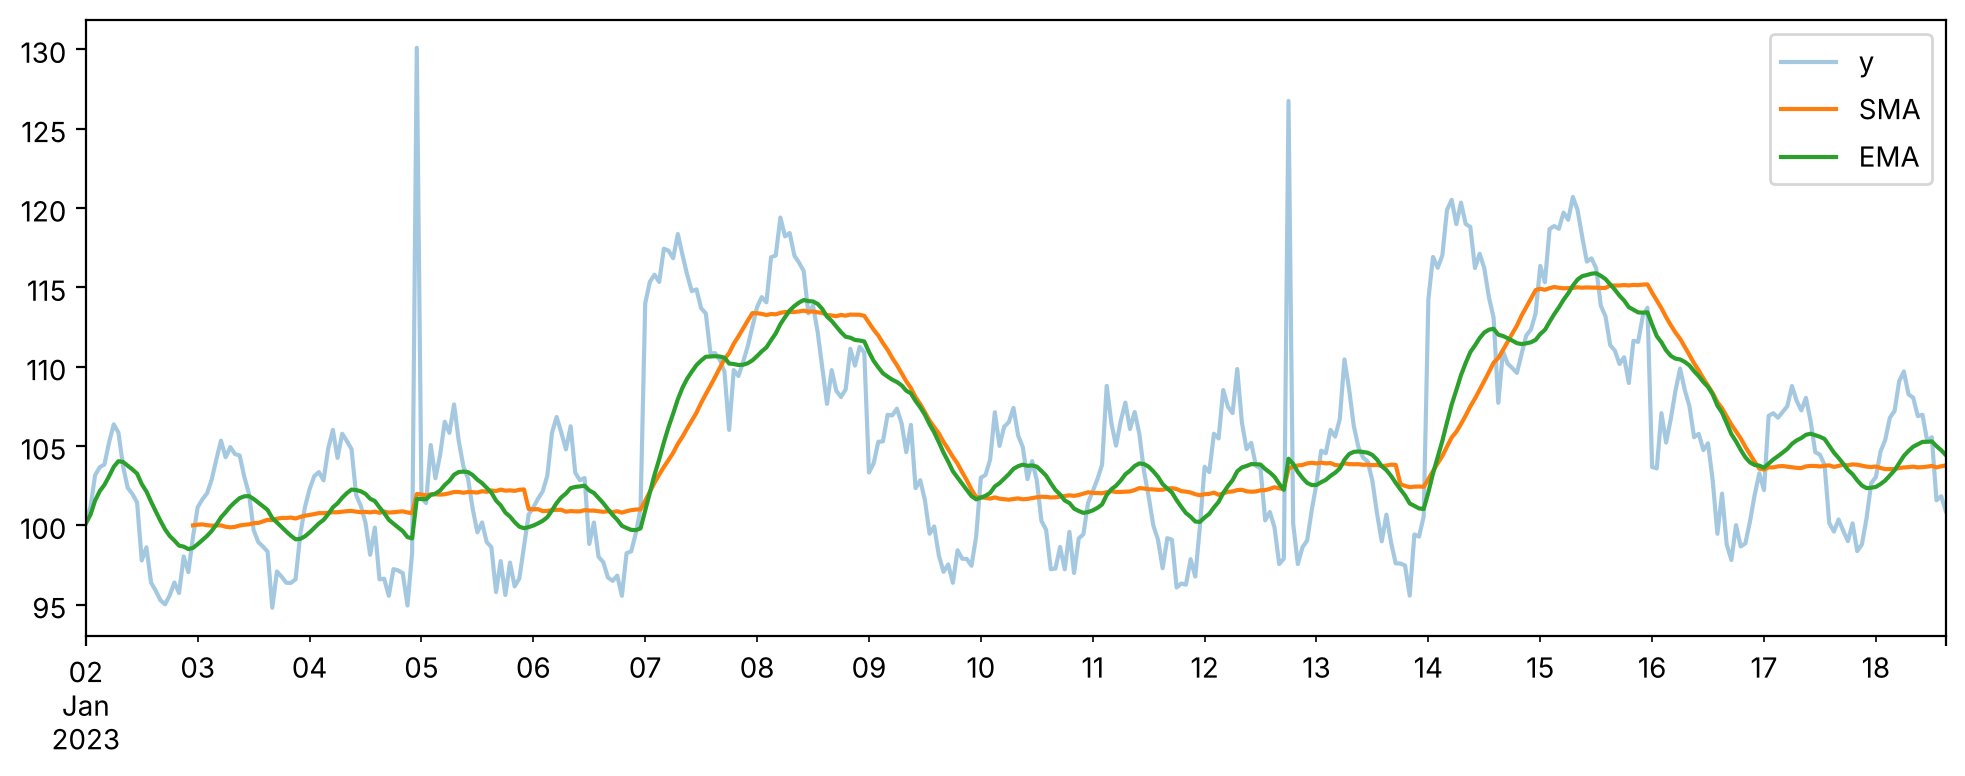

In [3]:
# SMA vs EMA
m = 24
y[:400].plot(figsize=(12, 4), alpha=0.4, label="y")
y.rolling(m).mean()[:400].plot(label="SMA")
y.ewm(alpha=2 / (m + 1)).mean()[:400].plot(label="EMA")
plt.legend(); plt.show()

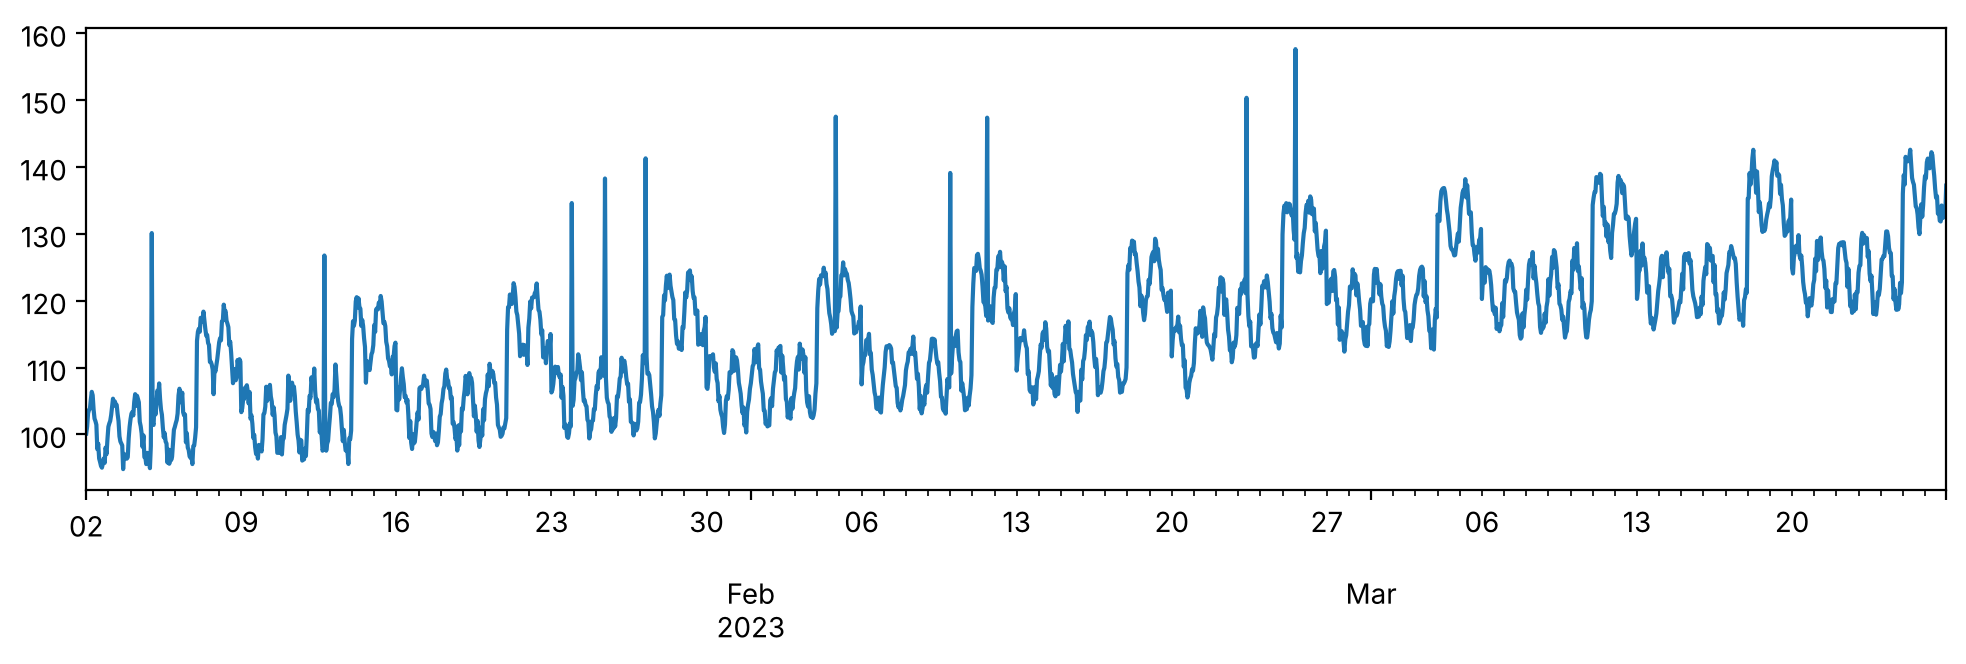

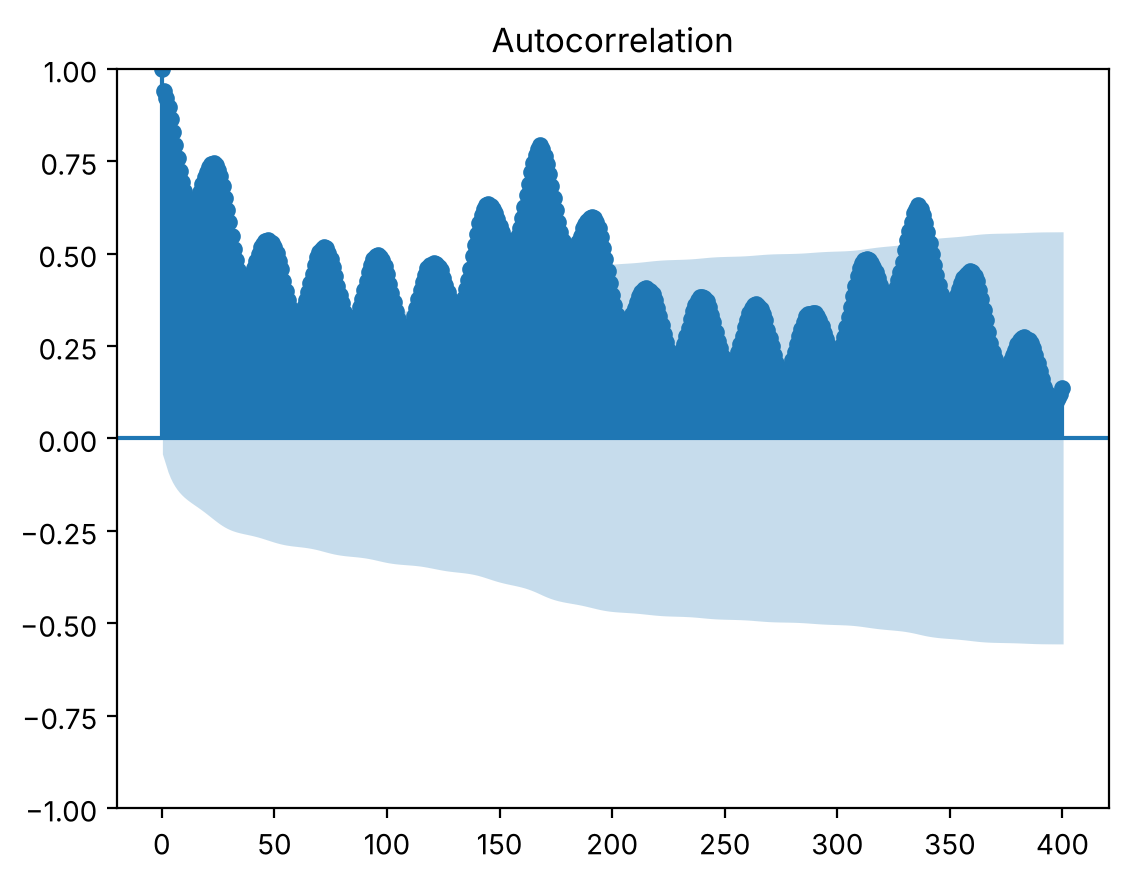

In [4]:
y.plot(figsize=(12, 3)); plt.show()
plot_acf(y, lags=400); plt.show()

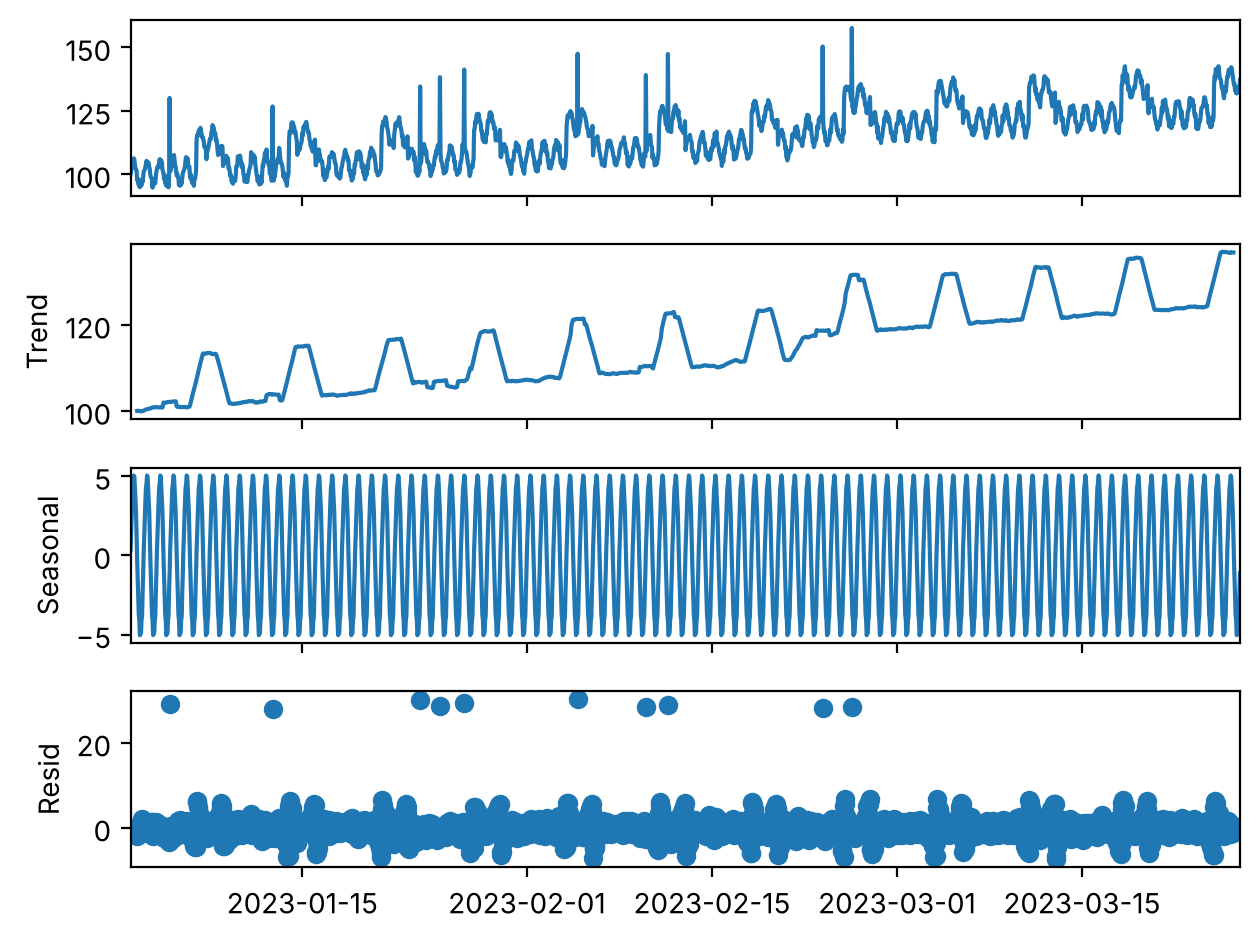

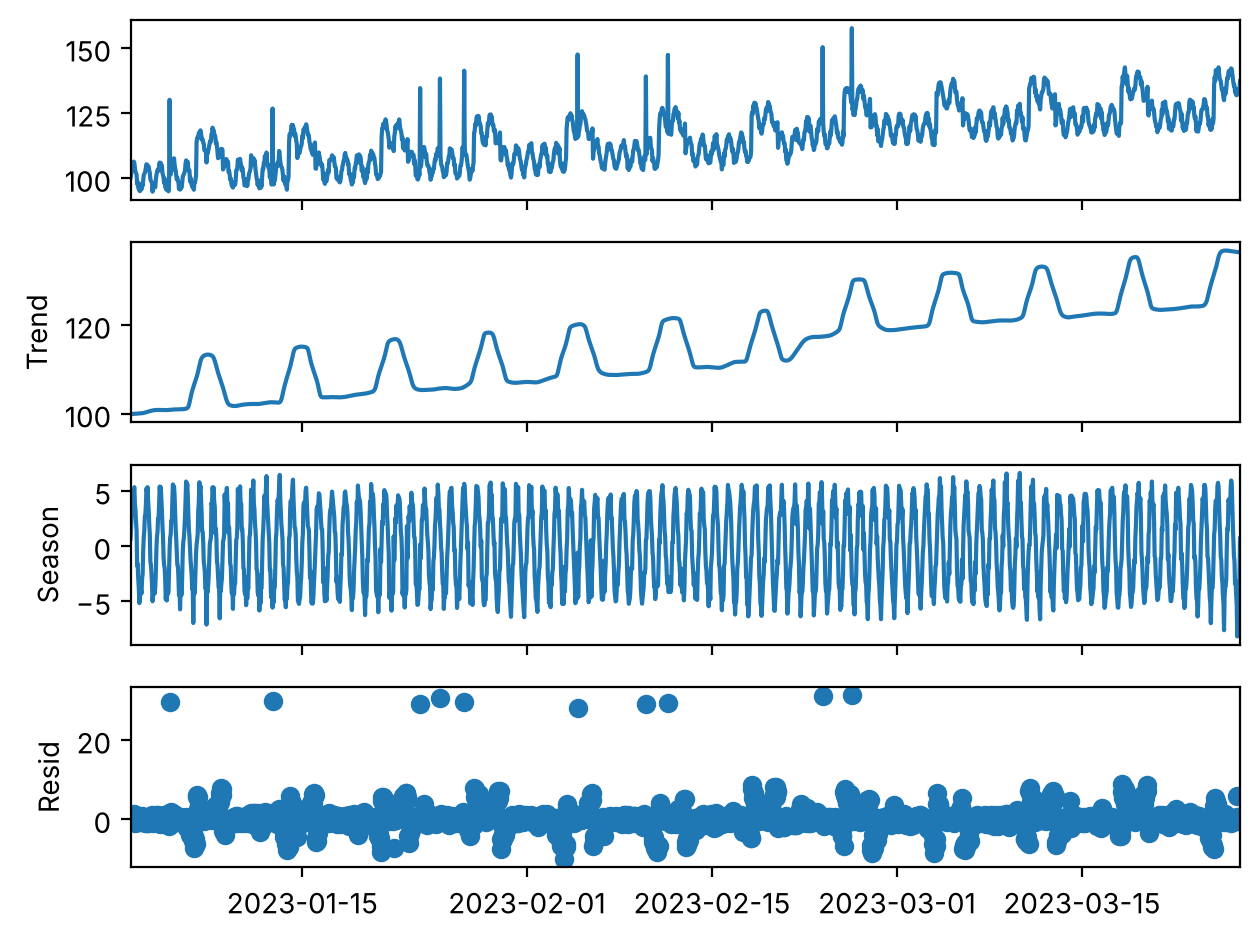

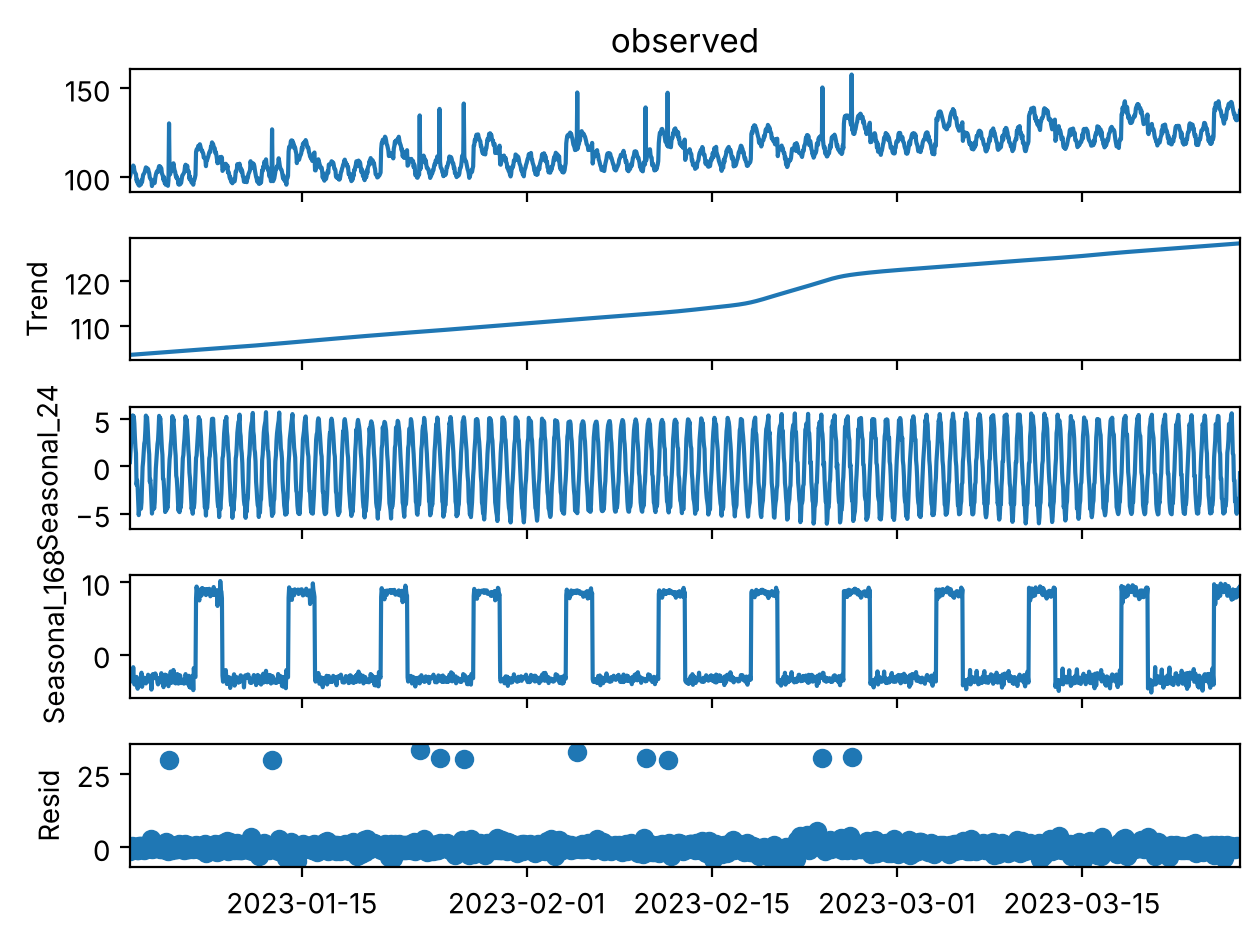

In [5]:
classic = seasonal_decompose(y, period=24)
stl = STL(y, period=24, robust=True).fit()
mstl = MSTL(y, periods=(24, 168), stl_kwargs={"robust": True}).fit()
for r in (classic, stl, mstl):
    r.plot(); plt.show()

In [6]:
def resid_stats(r):
    r = r.dropna(); a = acf(r, nlags=168)
    return {"var": r.var(), "acf24": a[24], "acf168": a[168]}

pd.DataFrame({"classic": resid_stats(classic.resid),
              "stl": resid_stats(stl.resid),
              "mstl": resid_stats(mstl.resid)}).T.round(3)

,var,acf24,acf168
classic,8.570,0.007,0.328
stl,9.784,-0.041,0.351
mstl,5.530,-0.025,-0.021


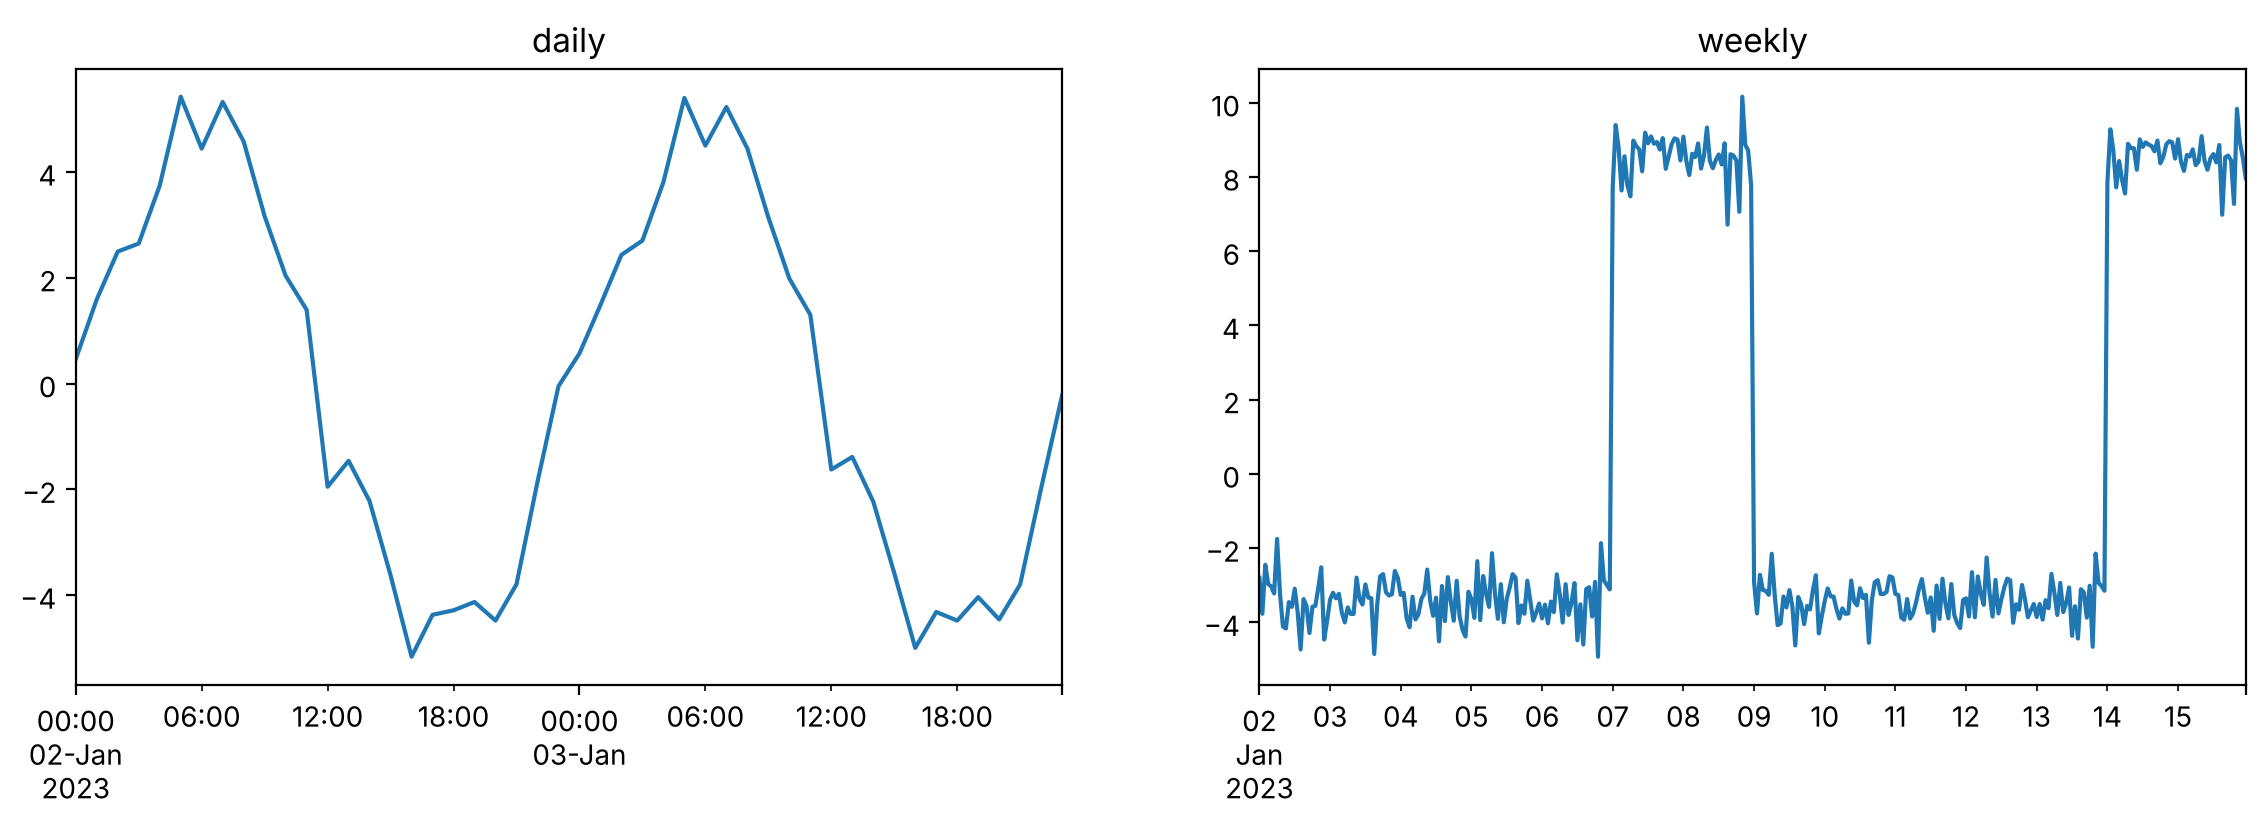

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
mstl.seasonal["seasonal_24"][:48].plot(ax=ax[0], title="daily")
mstl.seasonal["seasonal_168"][:336].plot(ax=ax[1], title="weekly"); plt.show()

In [8]:
# multiplicative series -> log + STL, tune parameters
tm = np.arange(144)
ym = pd.Series(100 * np.exp(0.01 * tm) * (1 + 0.2 * np.sin(2 * np.pi * tm / 12)) * np.exp(rng.normal(0, 0.03, 144)),
               index=pd.date_range("2012-01", periods=144, freq="MS"))
for season in (7, 13, 25):
    r = STL(np.log(ym), period=12, seasonal=season, robust=True).fit()
    print(f"seasonal={season}: resid var={r.resid.var():.6f}, acf12={acf(r.resid, nlags=12)[12]:.3f}")

seasonal=7: resid var=0.000709, acf12=-0.025
seasonal=13: resid var=0.000637, acf12=-0.085
seasonal=25: resid var=0.000661, acf12=-0.054


Conclusion: classical and STL leave the weekly cycle in the residual; MSTL removes both seasonalities.